In [4]:
%pip install scipy

   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
    --------------------------------------- 0.5/36.6 MB 4.7 MB/s eta 0:00:08
   ---- ----------------------------------- 3.7/36.6 MB 12.2 MB/s eta 0:00:03
   ----------- ---------------------------- 10.5/36.6 MB 20.8 MB/s eta 0:00:02
   ------------------ --------------------- 17.0/36.6 MB 23.6 MB/s eta 0:00:01
   --------------------------- ------------ 25.2/36.6 MB 27.2 MB/s eta 0:00:01
   ---------------------------------------  36.4/36.6 MB 32.6 MB/s eta 0:00:01
   ---------------------------------------- 36.6/36.6 MB 28.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import numpy as np
import pandas as pd
from scipy import stats

data = pd.read_csv('Data_TreatmentTimes.csv')
print(data.head())

#surgery = exponential lamda = 0.4237
#Gen Med Lognormal μ = 0.921, σ = 0.949
#Onco Gamma shape = 0.612, scale = 9.689
#Neuro Lognormal μ = 0.53, σ = 1.133

fitted_dists = {
    'Surg': stats.expon(loc=0, scale=1 / 0.4237),
    'Gen Med': stats.lognorm(s=0.949, loc=0, scale=np.exp(0.921)),
    'Onco': stats.gamma(a=0.612, loc=0, scale=9.689),
    'Neuro': stats.lognorm(s=1.133, loc=0, scale=np.exp(0.53)),
}

candidates = {
    'expon': stats.expon,
    'lognorm': stats.lognorm,
    'gamma': stats.gamma,
    #'weibull_min': stats.weibull_min,
}

#fit for these using goodness of fit - use ktest (Kolmogorov-Smirnov test)
t_specialities = ["Ortho", "Renal", "Card" , "Respi", "Gastro-Endo"]
fit_summary = []

time_col = 'Treatment Time (Days)'
speciality = 'Specialty'

def best_fit(sample):
    best = None 
    for name, dist in candidates.items():
        params = dist.fit(sample, floc=0)
        ks_stat, p_val = stats.kstest(sample, dist.cdf, args=params)
        if best is None or ks_stat < best['ks']:
            best = dict(name=name, dist=dist, params=params,
                        ks=ks_stat, p=p_val)
    return best


for spec, grp in data.groupby(speciality):
    #if spec in fitted_dists:
        #continue
    sample = grp[time_col].dropna().to_numpy()
    best = best_fit(sample)
    fitted_dists[spec] = best['dist'](*best['params'])
    fit_summary.append({
        'Specialty': spec,
        'number of samples': len(sample),
        'Best Distribution': best['name'],
        'Parameters (shape(s), loc, scale)': tuple(round(p, 4) for p in best['params']),
        'KS Statistic': round(best['ks'], 4),
        'KS p-value': round(best['p'], 4),
    })

print(pd.DataFrame(fit_summary).to_string(index=False))
print(data.head())
print(data[speciality].unique())

   ID  Treatment Time (Days)    Specialty
0   0               4.640229        Ortho
1   1               0.770322        Renal
2   2               1.911212         Card
3   3               4.199311        Respi
4   4               2.527663  Gastro_Endo
  Specialty  number of samples Best Distribution Parameters (shape(s), loc, scale)  KS Statistic  KS p-value
       Card               4321           lognorm               (0.9862, 0, 1.7772)        0.0103      0.7461
Gastro_Endo               3254             gamma               (0.8467, 0, 3.9863)        0.0067      0.9982
      Ortho               3425             gamma               (1.0147, 0, 5.4112)        0.0089      0.9455
      Renal               3244             gamma               (0.5122, 0, 9.4168)        0.0136      0.5833
      Respi               4321           lognorm               (1.1333, 0, 1.7179)        0.0106      0.7144
   ID  Treatment Time (Days)    Specialty
0   0               4.640229        Ortho
1   1     

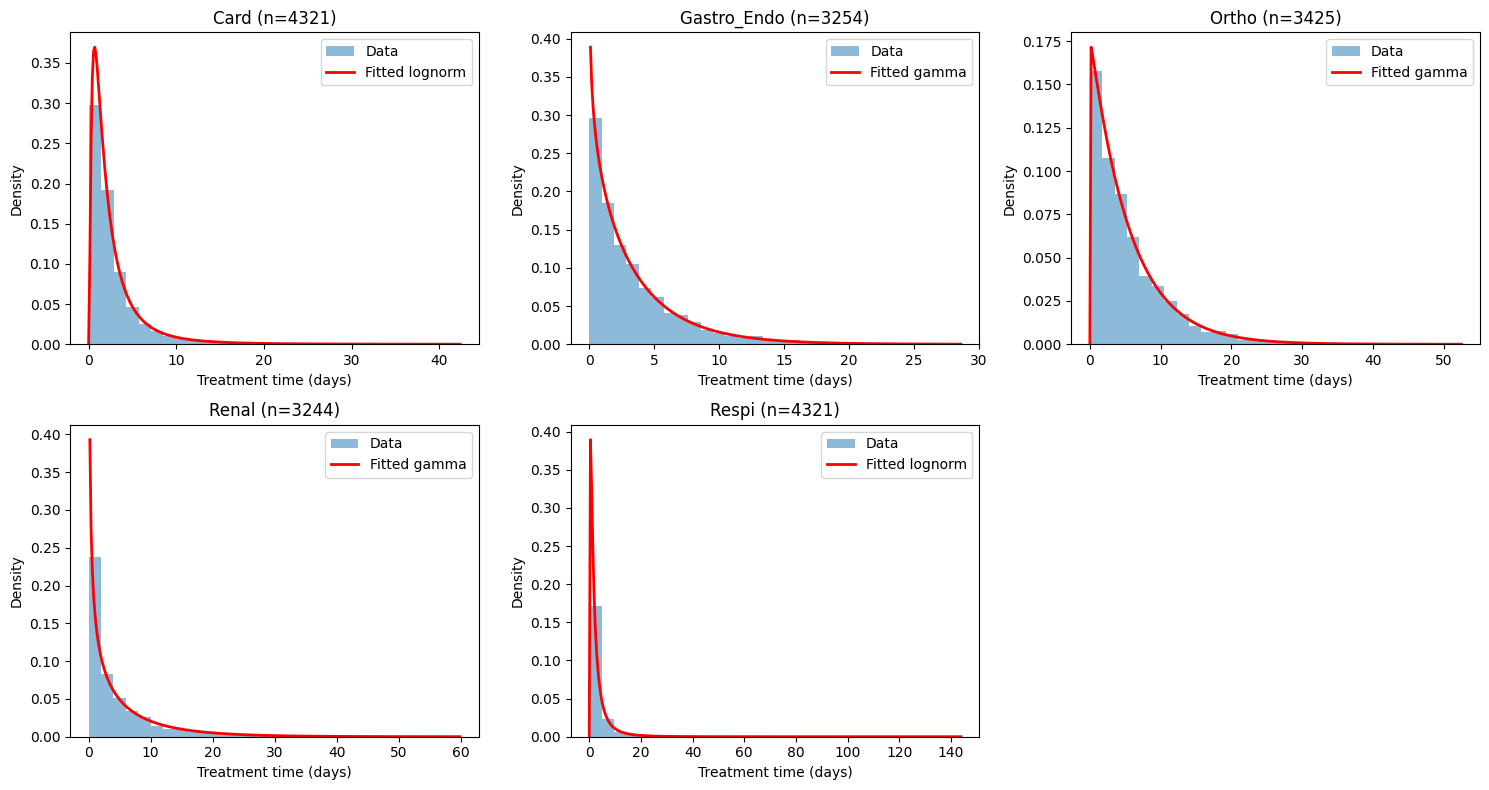

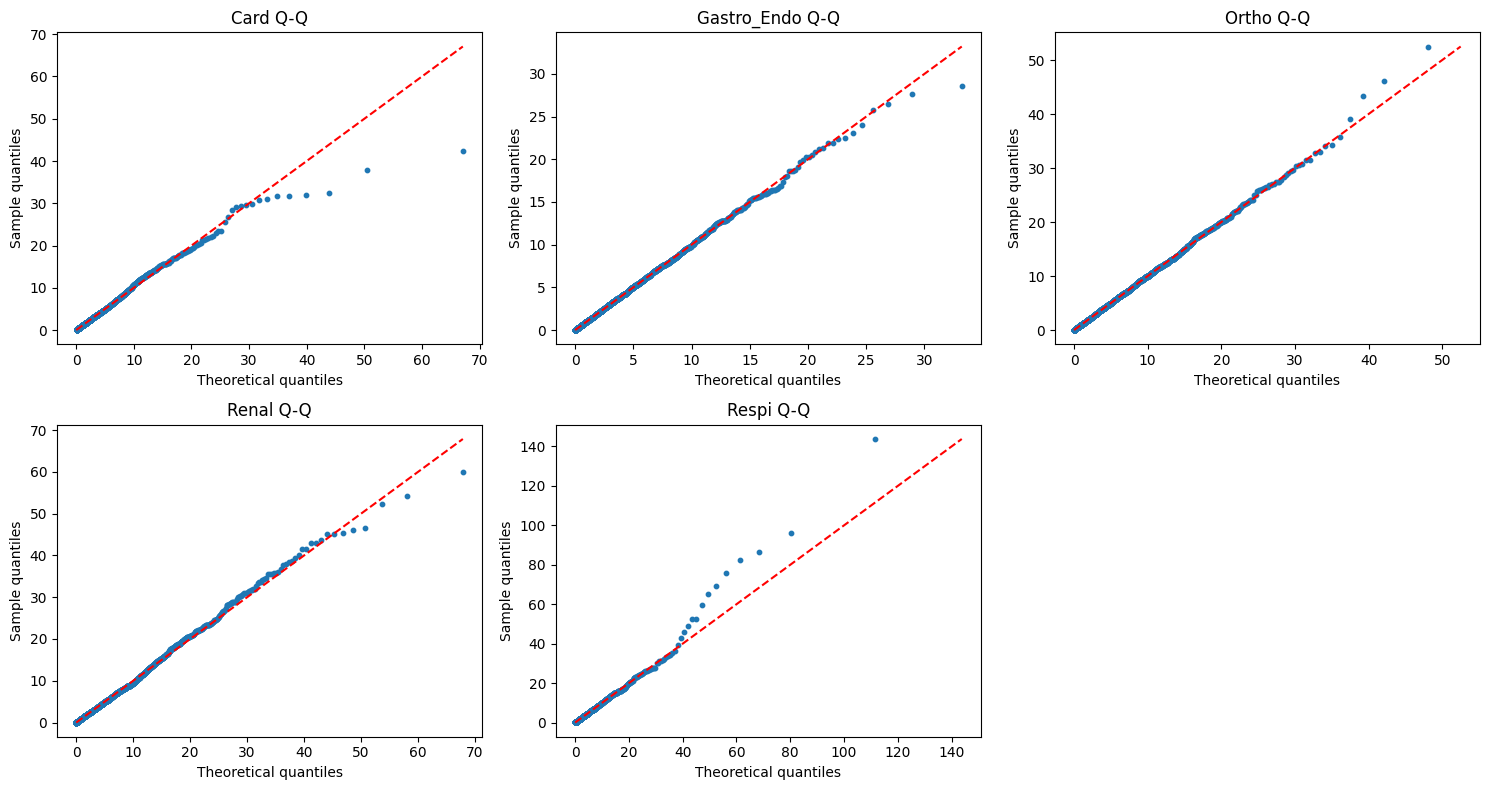

In [2]:
import matplotlib.pyplot as plt

summary_df = pd.DataFrame(fit_summary)
fitted_specs = summary_df['Specialty'].tolist()   # only the GoF-fitted specialties

n = len(fitted_specs)
ncols = 3
nrows = int(np.ceil(n / ncols))

#histogram with fit overlay
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, spec in zip(axes, fitted_specs):
    sample = data.loc[data[speciality] == spec, time_col].dropna().to_numpy()
    dist = fitted_dists[spec]
    best_name = summary_df.loc[summary_df['Specialty'] == spec, 'Best Distribution'].iloc[0]

    x = np.linspace(0, sample.max(), 300)
    ax.hist(sample, bins=30, density=True, alpha=0.5, label='Data')
    ax.plot(x, dist.pdf(x), 'r-', lw=2, label=f'Fitted {best_name}')
    ax.set_title(f'{spec} (n={len(sample)})')
    ax.set_xlabel('Treatment time (days)')
    ax.set_ylabel('Density')
    ax.legend()

for ax in axes[n:]:
    ax.axis('off')
plt.tight_layout()
plt.show()

#qq plots
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, spec in zip(axes, fitted_specs):
    sample = np.sort(data.loc[data[speciality] == spec, time_col].dropna().to_numpy())
    dist = fitted_dists[spec]
    probs = (np.arange(1, len(sample) + 1) - 0.5) / len(sample)
    theo = dist.ppf(probs)

    ax.scatter(theo, sample, s=10)
    lim = [0, max(theo.max(), sample.max())]
    ax.plot(lim, lim, 'r--')
    ax.set_title(f'{spec} Q-Q')
    ax.set_xlabel('Theoretical quantiles')
    ax.set_ylabel('Sample quantiles')

for ax in axes[n:]:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
print("hello")